# **Reto Final · Modelo predictivo de capturas de *Anopheles* en Cheté**

**Curso:** Aprendizaje Estadístico 2026-2

**Estudiantes:** Jeronimo Lopez Gomez – Jose Daniel Godoy

---

## Qué preguntas del reto responde este notebook

## Modelo: H1, la captura es proporcional al esfuerzo

- La estimación de Fermi dice que **capturas = tasa × colectores × horas × noches**. Lo incierto es la **tasa** (*Anopheles* por colector-hora); lo demás lo decide el equipo antes de salir.
- **H1** (sección 13 del EDA) supone que la captura es proporcional al esfuerzo, con una tasa estable. La pendiente log-log es compatible con 1 (b = 0.82 [0.43; 2.26] en Cheté), así que los datos la respaldan.
- **Modelo:** una `LinearRegression` de sklearn **sin intercepto**, $\hat N = \beta \times \text{colector-horas}$. La pendiente $\beta$ es la tasa de captura. Es la estimación de Fermi con la tasa calibrada con datos: la **Fermi revisada**.

## 1. Configuración y decisiones

- **Qué predecimos:** el número total de *Anopheles* en una campaña de 4 noches en Cheté.
- **Cuándo la predicción "funciona":** si su error absoluto medio (MAE) en campañas no vistas es **menor que el de la estimación de Fermi original**, nuestra referencia previa.
- **Campañas reservadas:** las 4 más recientes. No se usan para construir el modelo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

plt.rcParams.update({'figure.figsize': (11, 4.5), 'axes.grid': True, 'grid.alpha': 0.3})

RESERVADAS = ['2022-12', '2023-01', '2023-02', '2023-03']

# Diseño de la próxima campaña (caso central de EstimacionFermi.md)
COLECTORES, HORAS_POR_NOCHE, NOCHES = 5, 5, 4
COLECTOR_HORAS = COLECTORES * HORAS_POR_NOCHE * NOCHES
FERMI_ORIGINAL = 346
TASA_FERMI = FERMI_ORIGINAL / COLECTOR_HORAS
print(f'Esfuerzo de la próxima campaña: {COLECTOR_HORAS} colector-horas | tasa de Fermi: {TASA_FERMI:.2f}')

Esfuerzo de la próxima campaña: 100 colector-horas | tasa de Fermi: 3.46


## 2. Observación: una visita = una casa en una campaña

Especie × casa × campaña y suma varias noches. Por eso la **observación** es: una casa en una campaña mensual. Se suman las especies, y el **esfuerzo** es noches × horas (se supone un colector por casa).

La campaña (mes) se toma de `verbatimEventDate`, porque `eventDate` tiene nulos y errores de año.

In [2]:
MESES = {'enero': 1, 'febrero': 2, 'marzo': 3, 'abril': 4, 'mayo': 5, 'junio': 6, 'julio': 7,
         'agosto': 8, 'septiembre': 9, 'octubre': 10, 'noviembre': 11, 'diciembre': 12}

def mes_campania(texto):
    partes = str(texto).lower().split()
    if len(partes) == 2 and partes[0] in MESES:                  # 'enero 2023'
        return f'{partes[1]}-{MESES[partes[0]]:02d}'
    return str(texto)[:7]                                        # '2023-01-10/...' -> '2023-01'

occ = pd.read_csv('occurrence.txt', sep='\t', low_memory=False)
chete = occ[occ['locality'] == 'Cheté'].copy()
chete['casa'] = chete['parentEventID']
chete['campania'] = chete['verbatimEventDate'].map(mes_campania)
chete['noches'] = chete['samplingEffort'].str.extract(r'(\d+)\s*noche')[0].astype(float)
chete['horas'] = chete['samplingEffort'].str.extract(r'(\d+)\s*h')[0].astype(float)

visitas = (chete.groupby(['campania', 'casa'])
                .agg(N=('individualCount', 'sum'), noches=('noches', 'max'), horas=('horas', 'max'))
                .reset_index())
visitas['esfuerzo'] = visitas['noches'] * visitas['horas']        # colector-horas
visitas['tasa'] = visitas['N'] / visitas['esfuerzo']              # Anopheles por colector-hora

assert len(visitas) == 44 and visitas['N'].sum() == 7418
print(f"{len(visitas)} visitas, {visitas['campania'].nunique()} campañas, {visitas['N'].sum()} Anopheles")
visitas.head()

44 visitas, 22 campañas, 7418 Anopheles


,campania,casa,N,noches,horas,esfuerzo,tasa
0,2021-01,Chete1,202,3.0,14.0,42.0,4.809524
1,2021-01,Chete2,126,2.0,14.0,28.0,4.500000
2,2021-02,Chete1,78,2.0,14.0,28.0,2.785714
3,2021-02,Chete2,102,2.0,14.0,28.0,3.642857
4,2021-04,Chete1,272,3.0,12.0,36.0,7.555556


## 3. El modelo: regresión lineal sin intercepto (H1)

$$N_{\text{campaña}} = \beta \times \text{colector-horas}_{\text{campaña}} + \varepsilon$$

- **Observación para ajustar:** la **campaña** (las dos casas sumadas), porque las casas de un mismo mes no son independientes. Hay 18 campañas de entrenamiento.
- **Sin intercepto** (`fit_intercept=False`): con cero horas de captura no se captura nada. Así $\beta$ se lee directamente como *Anopheles* por colector-hora.
- **Comprobación de H1:** si la captura es proporcional al esfuerzo, agregar un intercepto no debería mejorar mucho el ajuste.

beta = 4.59 Anopheles por colector-hora (Fermi suponía 3.46) | R² = 0.42
Con intercepto: R² = 0.44 (intercepto = -106) -> el intercepto casi no mejora el ajuste: la captura es proporcional al esfuerzo


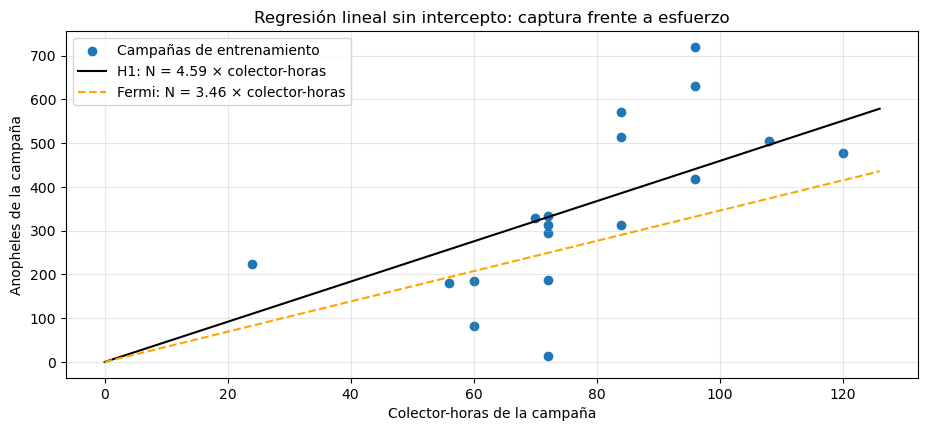

In [3]:
campanias = (visitas.groupby('campania')
             .agg(N=('N', 'sum'), esfuerzo=('esfuerzo', 'sum'))
             .reset_index())
entrenamiento = campanias[~campanias['campania'].isin(RESERVADAS)]

def ajustar(datos):
    """H1: N = beta × colector-horas (regresión lineal sin intercepto)."""
    return LinearRegression(fit_intercept=False).fit(datos[['esfuerzo']], datos['N'])

modelo = ajustar(entrenamiento)
BETA = modelo.coef_[0]
r2 = r2_score(entrenamiento['N'], modelo.predict(entrenamiento[['esfuerzo']]))

con_intercepto = LinearRegression().fit(entrenamiento[['esfuerzo']], entrenamiento['N'])
r2_con_intercepto = r2_score(entrenamiento['N'], con_intercepto.predict(entrenamiento[['esfuerzo']]))

print(f'beta = {BETA:.2f} Anopheles por colector-hora (Fermi suponía {TASA_FERMI:.2f}) | R² = {r2:.2f}')
print(f'Con intercepto: R² = {r2_con_intercepto:.2f} (intercepto = {con_intercepto.intercept_:.0f}) '
      f'-> el intercepto casi no mejora el ajuste: la captura es proporcional al esfuerzo')

x = np.linspace(0, entrenamiento['esfuerzo'].max() * 1.05, 50)
plt.scatter(entrenamiento['esfuerzo'], entrenamiento['N'], label='Campañas de entrenamiento')
plt.plot(x, BETA * x, 'k-', label=f'H1: N = {BETA:.2f} × colector-horas')
plt.plot(x, TASA_FERMI * x, '--', color='orange', label=f'Fermi: N = {TASA_FERMI:.2f} × colector-horas')
plt.xlabel('Colector-horas de la campaña'); plt.ylabel('Anopheles de la campaña'); plt.legend()
plt.title('Regresión lineal sin intercepto: captura frente a esfuerzo'); plt.show()

## 4. Validación respetando el tiempo

Para cada campaña de entrenamiento a partir de la 11ª, se ajusta la regresión **solo con las campañas anteriores** y se predice el **total de la campaña**. La comparación es contra **Fermi original**: 3.46 *Anopheles* por colector-hora × esfuerzo.

In [4]:
def comparar(lista_campanias, datos_previos):
    filas = []
    for c in lista_campanias:
        previas = datos_previos[datos_previos['campania'] < c]
        objetivo = campanias[campanias['campania'] == c]
        filas.append({'campania': c,
                      'observado': objetivo['N'].item(),
                      'h1': ajustar(previas).predict(objetivo[['esfuerzo']]).item(),
                      'fermi': TASA_FERMI * objetivo['esfuerzo'].item()})
    return pd.DataFrame(filas)

def errores(tabla):
    return pd.Series({col: mean_absolute_error(tabla['observado'], tabla[col]) for col in ['h1', 'fermi']},
                     name='MAE')

campanias_entren = sorted(entrenamiento['campania'])
validacion = comparar(campanias_entren[10:], entrenamiento)
display(validacion.round(0))
errores_validacion = errores(validacion)
errores_validacion.round(1)

,campania,observado,h1,fermi
0,2022-02,188,282.0,249.0
1,2022-03,224,92.0,83.0
2,2022-05,514,324.0,291.0
3,2022-07,294,293.0,249.0
4,2022-08,506,440.0,374.0
5,2022-09,571,349.0,291.0
6,2022-10,418,417.0,332.0
7,2022-11,720,417.0,332.0


h1       126.0
fermi    169.6
Name: MAE, dtype: float64

## 5. Evaluación final en las campañas reservadas

Se usan una sola vez: la regresión ajustada con las 18 campañas de entrenamiento predice cada campaña reservada.

,campania,observado,h1,fermi
0,2022-12,249,441.0,332.0
1,2023-01,421,441.0,332.0
2,2023-02,277,441.0,332.0
3,2023-03,180,441.0,332.0


h1       159.3
fermi     94.8
Name: MAE, dtype: float64

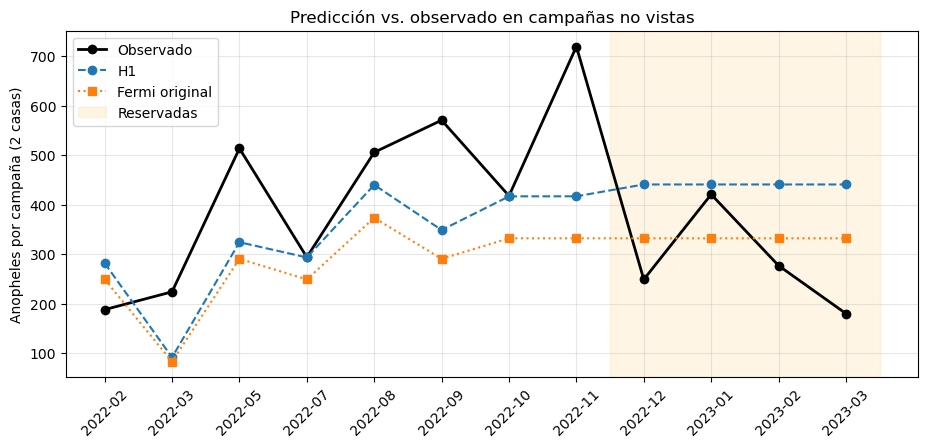

In [5]:
evaluacion = comparar(RESERVADAS, entrenamiento)
display(evaluacion.round(0))
errores_final = errores(evaluacion)
display(errores_final.round(1))

fig, ax = plt.subplots()
tabla = pd.concat([validacion, evaluacion])
ax.plot(tabla['campania'], tabla['observado'], 'ko-', lw=2, label='Observado')
ax.plot(tabla['campania'], tabla['h1'], 'o--', label='H1')
ax.plot(tabla['campania'], tabla['fermi'], 's:', label='Fermi original')
ax.axvspan(len(validacion) - 0.5, len(tabla) - 0.5, color='orange', alpha=0.1, label='Reservadas')
ax.set(ylabel='Anopheles por campaña (2 casas)', title='Predicción vs. observado en campañas no vistas')
ax.tick_params(axis='x', rotation=45); ax.legend(); plt.show()

## 6. Predicción de la próxima campaña, con incertidumbre

Diseño de Fermi: 5 colectores × 5 h × 4 noches = 100 colector-horas. La regresión se ajusta con **las 22 campañas**.

- **Predicción:** $\hat N = \hat\beta \times 100$.
- **IC 95 % del valor esperado:** bootstrap de campañas. Se remuestrean las 22 campañas con reemplazo, se reajusta la regresión y se toma el percentil 2.5 y el 97.5 de $\hat\beta \times 100$.
- **Rango de una campaña nueva (80 %):** se aplica la tasa real de **cada** campaña histórica al diseño de Fermi; el percentil 10 y el 90 de esos 22 valores dicen cuánto puede variar una campaña concreta.

beta = 4.20 (IC 95 %: 3.44 - 4.95) Anopheles por colector-hora
Anopheles esperados: 420 (IC 95 %: 344 - 495)
Rango 80 % de una campaña nueva (P10-P90 de las 22 campañas): 195 - 677 | Fermi original: 346


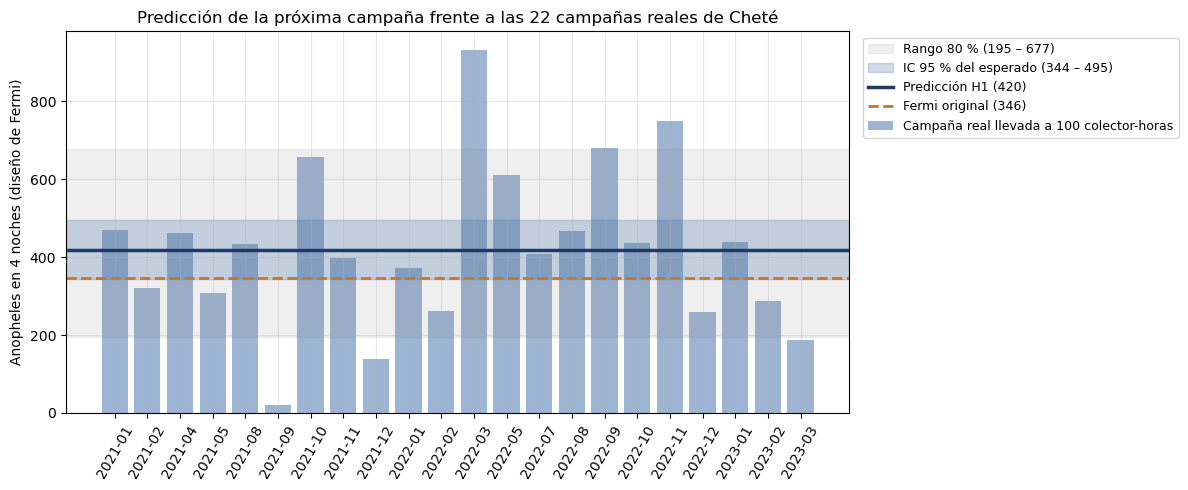

In [6]:
rng = np.random.default_rng(2026)   # semilla fija: esta celda da siempre el mismo resultado

modelo_final = ajustar(campanias)
beta_final = modelo_final.coef_[0]
esperado = beta_final * COLECTOR_HORAS

# IC 95 % del valor esperado: bootstrap de campañas
betas = [ajustar(campanias.iloc[rng.integers(0, len(campanias), len(campanias))]).coef_[0] for _ in range(5000)]
beta_inf, beta_sup = np.percentile(betas, [2.5, 97.5])

# Rango 80 %: cada campaña real llevada al diseño de Fermi
reales_en_fermi = campanias['N'] / campanias['esfuerzo'] * COLECTOR_HORAS
p10, p90 = np.percentile(reales_en_fermi, [10, 90])

print(f'beta = {beta_final:.2f} (IC 95 %: {beta_inf:.2f} - {beta_sup:.2f}) Anopheles por colector-hora')
print(f'Anopheles esperados: {esperado:.0f} (IC 95 %: {beta_inf * COLECTOR_HORAS:.0f} - {beta_sup * COLECTOR_HORAS:.0f})')
print(f'Rango 80 % de una campaña nueva (P10-P90 de las 22 campañas): {p10:.0f} - {p90:.0f} | Fermi original: {FERMI_ORIGINAL}')

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(campanias['campania'], reales_en_fermi, color='#9DB4D3', label='Campaña real llevada a 100 colector-horas')
ax.axhspan(p10, p90, color='gray', alpha=0.12, label=f'Rango 80 % ({p10:.0f} – {p90:.0f})')
ax.axhspan(beta_inf * COLECTOR_HORAS, beta_sup * COLECTOR_HORAS, color='#4472A8', alpha=0.25,
           label=f'IC 95 % del esperado ({beta_inf * COLECTOR_HORAS:.0f} – {beta_sup * COLECTOR_HORAS:.0f})')
ax.axhline(esperado, color='#1F3B63', lw=2.5, label=f'Predicción H1 ({esperado:.0f})')
ax.axhline(FERMI_ORIGINAL, color='#C07836', lw=2, ls='--', label=f'Fermi original ({FERMI_ORIGINAL})')
ax.set(ylabel='Anopheles en 4 noches (diseño de Fermi)',
       title='Predicción de la próxima campaña frente a las 22 campañas reales de Cheté')
ax.tick_params(axis='x', rotation=60)
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=9)
plt.tight_layout(); plt.show()

**Cómo leer la gráfica.** Cada barra es una campaña real de Cheté: cuántos *Anopheles* habría dado si se hubiera hecho con el diseño de Fermi (su tasa × 100 colector-horas).
- La **línea azul oscura** es la predicción (420).
- La **franja azul** es su IC 95 %: dónde está el valor típico de una campaña, con buena confianza (344 – 495).
- La **franja gris** muestra que una campaña concreta varía mucho más: 8 de cada 10 caen entre 195 y 677.
- Fermi (346) queda por debajo de la predicción, pero dentro de lo que se observa en la práctica.

### Tabla de resultados

Son los valores que salen de las §2 a §6 (semilla fija = 2026, así que se repiten siempre). En la §7 se citan con el nombre de la columna **Variable**.

| Pregunta | Variable | Valor | Descripción |
|---|---|---:|---|
| P1 | `P1_visitas` | 44 | Número de visitas (casa × campaña) |
| P1 | `P1_campanias` | 22 | Número de campañas mensuales (observaciones del modelo) |
| P2 | `P2_beta` | 4.20 | Pendiente β: *Anopheles* por colector-hora (22 campañas) |
| P2 | `P2_beta_ic95` | 3.44 – 4.95 | IC 95 % de β (bootstrap de campañas) |
| P2 | `P2_esperado` | 420 | *Anopheles* esperados en 4 noches (β × 100 colector-horas) |
| P2 | `P2_esperado_ic95` | 344 – 495 | IC 95 % del valor esperado |
| P2 | `P2_rango80` | 195 – 677 | Rango 80 % de una campaña nueva (P10 – P90 de las 22 campañas reales) |
| P3 | `P3_r2` | 0.42 | R² de la regresión sin intercepto (entrenamiento) |
| P3 | `P3_r2_con_intercepto` | 0.44 | R² si se agrega intercepto (casi igual: H1 se sostiene) |
| P3 | `P3_mae_val_h1` | **126** | MAE en validación · regresión lineal (H1) |
| P3 | `P3_mae_val_fermi` | 170 | MAE en validación · Fermi original |
| P3 | `P3_mae_res_h1` | 159 | MAE en reservadas · regresión lineal (H1) |
| P3 | `P3_mae_res_fermi` | **95** | MAE en reservadas · Fermi original |
| P4 | `P4_tasa_fermi` | 3.46 | Tasa supuesta por Fermi (*Anopheles* por colector-hora) |
| P4 | `P4_fermi_en_ic95_beta` | Sí (justo) | La tasa de Fermi queda en el borde inferior del IC 95 % de β |
| P5 | `P5_planear_para` | 677 | *Anopheles* para los que conviene empacar (percentil 90) |

## 7. Respuestas a las preguntas del reto

> Cada cifra viene de la **Tabla de resultados** anterior; entre paréntesis está el nombre de su variable.

### 1. ¿Qué es una observación?
Una **visita** es una casa en una campaña mensual: en Cheté hay **44** (`P1_visitas`). Para el modelo se suman las dos casas de cada mes, porque no son independientes; la observación es la **campaña**, y hay **22** (`P1_campanias`). El esfuerzo se mide en **colector-horas** (noches × horas por noche), suponiendo un colector por casa.

### 2. ¿Qué predecimos?
El **total de *Anopheles* en una campaña de 4 noches** con el diseño de Fermi (5 colectores × 5 h × 4 noches = 100 colector-horas). Usamos una **regresión lineal sin intercepto**, $N = \beta \times \text{colector-horas}$, con solo información conocida antes de salir: el **esfuerzo**, que lo decide el equipo.

| Próxima campaña | Valor | Variable |
|---|---:|---|
| Tasa β (*Anopheles* por colector-hora) | **4.20** (IC 95 %: 3.44 – 4.95) | `P2_beta`, `P2_beta_ic95` |
| *Anopheles* esperados | **420** (IC 95 %: 344 – 495) | `P2_esperado`, `P2_esperado_ic95` |
| Rango 80 % de una campaña nueva | 195 – 677 | `P2_rango80` |

### 3. ¿Funciona la predicción?
- **Ajuste:** R² = **0.42** (`P3_r2`). El esfuerzo explica el 42 % de la variación entre campañas. Agregar un intercepto apenas lo sube a 0.44 (`P3_r2_con_intercepto`), así que la captura es **proporcional al esfuerzo**: H1 se sostiene.

| MAE (Anopheles por campaña) | **Regresión (H1)** | Fermi original |
|---|---:|---:|
| Validación temporal (8 campañas) | **126** (`P3_mae_val_h1`) | 170 (`P3_mae_val_fermi`) |
| Campañas reservadas (4 campañas) | 159 (`P3_mae_res_h1`) | **95** (`P3_mae_res_fermi`) |

**Cumple a medias.** La regresión gana en la validación (126 frente a 170), pero en las 4 campañas reservadas Fermi tuvo menos error (95 frente a 159). Esas 4 campañas fueron todas bajas (180 – 421), y Fermi supone una tasa más baja. Con solo 4 campañas, esa diferencia puede deberse al azar.

### 4. ¿Cómo queda la estimación de Fermi?
Fermi estimó **346** *Anopheles* con una tasa de **3.46** por colector-hora (`P4_tasa_fermi`). La regresión estima **β = 4.20**, un 21 % más alta, y por eso espera **420**. La tasa de Fermi queda justo en el borde inferior del IC 95 % de β (`P4_fermi_en_ic95_beta`). El supuesto central de Fermi, **captura = tasa × esfuerzo, resistió**; la tasa supuesta se quedó algo corta.

### 5. ¿Le sirve el modelo al equipo?
**Sí, como herramienta de planeación.** Es una regresión lineal simple, se apoya en los datos y supera a Fermi en la validación. Pero la variación entre campañas es grande: la diferencia entre casas y entre meses no se puede anticipar.

**Recomendación para empacar:** llevar material para unos **680 *Anopheles*** (`P5_planear_para`, percentil 90). Así el equipo queda cubierto en 9 de cada 10 campañas, mientras que el valor esperado es de ~420.

### Limitaciones
- Solo hay 2 casas y 22 campañas.
- Se supone un colector por casa; si fueran dos, la tasa por colector-hora sería la mitad.
- La tasa del estudio se midió con 12 h por noche y se aplica a las 5 h del diseño de Fermi.
- Las campañas reservadas ya se habían mirado una vez en `modelo.py`.

## 8. Lo que nos preguntamos en campo (punto 4 del reto)

a) Podría haber grandes variaciones entre las distintas casas, por razones que no fueron tomadas en cuenta y que subyacen a estas.

b) Habría que preguntarse por el flujo de mosquitos dentro de las casas. Por ejemplo, podría haber casas que se mantienen más cerradas y otras que dejan más ventanas abiertas.

c) ¿Por qué localidades vecinas capturan especies distintas? Cheté es casi solo *An. albimanus*, y San Miguel del Río, casi solo *An. neivai*.

d) ¿La campaña de septiembre de 2021, con capturas casi nulas, fue real o un error de registro?

e) ¿Influye la persona que hace de colector? La captura es con cebo humano.

**Respondemos la a) con los datos,** comparando las dos casas de Cheté en el mismo mes:

Tasa global: Chete1 = 6.56 | Chete2 = 1.59 Anopheles por colector-hora
Chete1 capturó más que Chete2 en 21 de 22 meses | razón mediana = 4.2


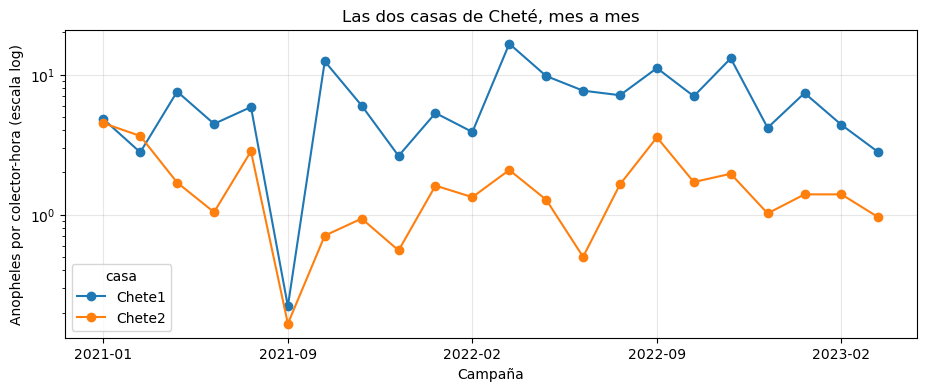

In [42]:
from scipy import stats

por_casa = visitas.pivot(index='campania', columns='casa', values='tasa')
razon = por_casa['Chete1'] / por_casa['Chete2']
tasa_global = visitas.groupby('casa')['N'].sum() / visitas.groupby('casa')['esfuerzo'].sum()

print(f"Tasa global: Chete1 = {tasa_global['Chete1']:.2f} | Chete2 = {tasa_global['Chete2']:.2f} Anopheles por colector-hora")
print(f"Chete1 capturó más que Chete2 en {(razon > 1).sum()} de {len(razon)} meses | razón mediana = {razon.median():.1f}")

ax = por_casa.plot(marker='o', logy=True, figsize=(11, 4))
ax.set(ylabel='Anopheles por colector-hora (escala log)', xlabel='Campaña',
       title='Las dos casas de Cheté, mes a mes'); plt.show()

**Respuesta:** sí. Chete1 captura unas **4 veces más** que Chete2.

## 9. Lo que decidimos

- **Observación:** cada registro es un evento de detección con sus características. Para comparar, se suman en **visitas** (casa × campaña) y, en el modelo, en **campañas**, porque las casas de un mismo mes no son independientes.

- **Qué predecimos:** el número de *Anopheles* capturados en la campaña (~420), y con eso los de cada colector (~84 en las 4 noches), para saber cuántos recursos se necesitan.

- **Cuándo funciona:** si los recursos sobran por un poco más de lo previsto. En la práctica, empacar para el percentil 90 (~680) debe alcanzar en 9 de cada 10 campañas.

**¿Qué campañas se pueden comparar?** Cuando los lugares y las duraciones son distintos, lo primero es determinar con las pruebas anteriores si los datos se pueden mezclar.

- **Duraciones:** se comparan **tasas por colector-hora**, no conteos, porque la captura es proporcional al esfuerzo (H1).

- **Especies:** importan. Se calcula la tasa de cada especie con el esfuerzo de la visita, y para predecir una especie se multiplica el total por su proporción histórica. En Cheté, el 98 % es *An. albimanus*.

- **Temporada:** caracteriza cada campaña, pero en los datos el mes y la lluvia no mejoraron la predicción.

**¿Qué revisar antes de confiar en un dato?** Un dato que sí se anotó se caracteriza porque pasó por el proceso posterior de caracterización entomológica (sílica gel y ELISA). El dataset solo registra presencias, así que una noche sin capturas no aparece. Por eso, en nuestra hoja de campo anotaremos también los ceros.

**¿Vale la pena comprobar la temporada de lluvias?** Sí, con los datos de precipitación del IDEAM. En esta zona llueve mucho todo el año, y la relación entre lluvia y captura resultó débil (EDA §9–§11), así que la temporada no cambia mucho la predicción.

**Una medición más:** el **conteo por hora de cada colector**, incluidas las horas sin capturas y anotando si está dentro o fuera de la casa. Permitiría saber si nuestras 5 h de captura rinden igual que las 12 h del estudio, y verificar los supuestos de Fermi sobre franjas e interior/exterior.

**¿Qué no se puede responder con estos datos?** ¿Qué características especiales pueden tener ciertas casas para ser las más o las menos concurridas? Los registros permiten comparar capturas entre lugares, pero no describen las viviendas ni sus alrededores. Desconocemos si mantienen las ventanas abiertas, si están rodeadas de vegetación o si hay depósitos de agua cercanos. Podemos identificar diferencias entre lugares, pero no explicar sus causas.